# Tracking giocatori: YOLO + ByteTrack

Detection e tracking multi-oggetto, senza riaddestramento. Usa il checkpoint giocatori locale e solo la classe `player`, non `refree`. Una baseline COCO `person` e ammessa solo con consenso esplicito in configurazione e puo includere arbitri/pubblico. Non riconosce squadre, ruoli, numeri maglia o identita fisiche: gli ID sono temporanei, possono cambiare dopo occlusioni/sostituzioni e non vengono riciclati per restare sotto 12.

**Limite restituito: massimo 6 ID per meta, quindi massimo 12 per frame** (`ENABLE_SIDE_CAP=True`). Non vengono inventati individui per raggiungere 12: possono essercene meno, e gli ID storici non sono il numero di persone nel frame. Le meta A=Y<9m e B=Y>=9m sono stime geometriche dei piedi, anche oltre i fondocampo, NON identita di squadra/maglia; Y=9 appartiene solo a B. Dopo il filtro sinistro si candidano soltanto track associate a detection correnti, non predizioni perse o box senza ID. Se una meta supera 6, precedenza agli ID gia ammessi nel frame precedente **sulla stessa meta attuale**, poi confidence YOLO corrente decrescente, anzianita della track in update decrescente, infine ID crescente. Non si penalizza un ID consolidato per una singola nuova confidence piu alta. Un cambio lato segue i piedi correnti, viene registrato e perde priorita sul vecchio lato; non si trasferiscono ID all'altra meta per riempire posti. Dopo un frame senza osservazione la priorita precedente termina. Il cap non classifica giocatori veri, non elimina duplicati garantiti, non corregge la calibrazione e puo scartare un atleta a favore di un falso positivo gia stabile. Accuratezza/ID switches richiedono GT, qui non disponibili.

Il cap richiede `ROI_MODE='floor'` e H pavimento valida. Per image/none occorre disabilitare **esplicitamente** `ENABLE_SIDE_CAP=False`, rinunciando alla garanzia6/12; nessuna assegnazione squadra fittizia in assenza di coordinate. Il parametro `EXPECTED_PLAYERS=12` resta diagnostica, non obiettivo minimo.

ByteTrack di Ultralytics contiene gia un Kalman interno: non ne aggiungiamo un altro. Il notebook mantiene **una sola istanza BYTETracker** per tutta la clip (persistenza esplicita, equivalente allo scopo di `persist=True`, senza callback che possano azzerarla ogni frame). Ogni update corrisponde a stride/FPS secondi video; velocita interne sono per frame campionato. Un nuovo avvio della cella crea una run e tracker nuovi. Stride elevati riducono la qualita delle associazioni: preferire 1.

Per il campo si usa soltanto l'omografia del pavimento, mai la camera 3D fallita: piede approssimato = centro del bordo inferiore della bbox YOLO. Salti/occlusioni/box imprecisi rendono questa stima incerta. ROI opzionale: `floor` (default con calibrazione coerente), `image` (poligono manuale) oppure `none` (nessun filtro esplicito). Nessuna calibrazione viene modificata.

**Filtro temporale, solo bordo sinistro in modalita floor:** ByteTrack associa prima tutte le detection player con piedi validi nell'immagine. Solo **X < -COURT_MARGIN_M**, cioe X < -0.25m, incrementa il contatore per ID. X=0 e il bordo sinistro (verificato con calibrazione e proiezioni a Y=0,9,18m). `MAX_OUTSIDE_COURT_UPDATES=10` mantiene le prime 9 osservazioni fuori a sinistra, poi esclude l'ID da video, conteggio attivo e CSV principale. A stride1/30fps sono circa0.33s video. **X >= -0.25m azzera il contatore e riabilita anche un ID gia escluso.** Bordo destro e fondocampo non provocano esclusione, anche se il punto e fuori dal rettangolo9x18m: non e un filtro globale in campo. Gap senza detection interrompe la consecutivita; geometria non valida non prova permanenza fuori e non produce osservazioni ammesse. Dopo soglia l'ID resta soppresso finche non rientra dal lato sinistro o scade nel tracker. La traccia interna non viene eliminata, per non ricreare subito un ID; nuovi ID possono comunque riavviare la tolleranza. `image` mantiene la precedente regola sull'intero poligono (esclusione fino scadenza ID), `none` la disattiva. Non e un classificatore allenatore: staff entro margine puo restare e atleti fuori a sinistra a lungo possono essere esclusi. Salti/occlusioni/box imprecisi rendono i piedi approssimati.

Gli output salvati nelle celle e nelle vecchie run sono storici e NON cambiano con questo codice. Dopo aver riaperto il notebook aggiornato dal disco, riavvia il kernel ed esegui tutte le celle; per floor verifica nella nuova `configurazione.json` margine0.25 e `outside_gate_version=post_association_left_sideline_only_v3`.

In [7]:
import os
os.environ['YOLO_AUTOINSTALL'] = 'false'  # prima di ogni import Ultralytics: nessuna installazione automatica
import importlib.util
import inspect
import json
import math
import hashlib
import sys
from pathlib import Path
from datetime import datetime
from types import SimpleNamespace
from uuid import uuid4

WORKSPACE_DIR = next((p.resolve() for p in (Path.cwd(), *Path.cwd().parents)
                      if (p / 'Annotazioni').is_dir() and (p / 'runs').is_dir()), None)
if WORKSPACE_DIR is None:
    raise FileNotFoundError('Avvia il notebook dalla cartella Scout_Volley_CV&NLP o da una sua sottocartella.')
CHECKPOINTS = sorted((WORKSPACE_DIR / 'runs' / 'volleyball_players').glob('**/weights/best.pt'))
VIDEOS = sorted(p for p in (WORKSPACE_DIR / 'Annotazioni').iterdir()
                if p.suffix.lower() in {'.mp4', '.avi', '.mov', '.mkv'})
for i, p in enumerate(CHECKPOINTS, 1):
    print('Checkpoint', i, p.relative_to(WORKSPACE_DIR))
for i, p in enumerate(VIDEOS, 1):
    print('Video', i, p.relative_to(WORKSPACE_DIR))

CHECKPOINT_INDEX = 1 if len(CHECKPOINTS) == 1 else None
VIDEO_INDEX = 1 if len(VIDEOS) == 1 else None
ALLOW_COCO_BASELINE = False  # solo se mancano pesi giocatori; person include arbitri/spettatori
COCO_WEIGHTS_PATH = WORKSPACE_DIR / 'yolov8m.pt'
START_SECONDS, END_SECONDS = 360, 4970
FRAME_STRIDE = 1
IMAGE_SIZE = 640
DETECTION_CONFIDENCE = 0.10  # basso per il secondo stadio ByteTrack
DISPLAY_CONFIDENCE = 0.40  # conteggio detection affidabili e box non ancora associati
NMS_IOU = 0.50
MAX_DETECTIONS = 100  # NON top12
TRACK_HIGH_THRESHOLD = 0.40
NEW_TRACK_THRESHOLD = 0.40
TRACK_LOST_SECONDS = 1.0
MATCH_THRESHOLD = 0.80
REQUEST_GPU = True
EXPECTED_PLAYERS = 12
EXPECTED_PER_HALF = 6
ENABLE_SIDE_CAP = True  # massimo 6 ID per meta/12 totali; richiede ROI_MODE=floor e omografia valida
ROI_MODE = 'floor'  # floor | image | none: scelta esplicita, nessun fallback silenzioso
COURT_MARGIN_M = 0.25  # tolleranza metrica oltre linee campo; nessun clamp delle coordinate
MAX_OUTSIDE_COURT_UPDATES = 10  # esclusione al decimo campione consecutivo fuori ROI, non dieci frame sorgente
IMAGE_ROI_POINTS = None  # solo ROI_MODE='image': lista di vertici [x_px, y_px]
CALIBRATION_PATH = None  # None cerca solo il file con nome del video selezionato
SAMPLE_INTERVAL_SECONDS = 1.0
MAX_SAMPLES = 3
MAX_CLIP_SECONDS = 1e8

def select_file(paths, index, label):
    if index is None or isinstance(index, bool) or not isinstance(index, int) or not 1 <= index <= len(paths):
        raise ValueError(f'Seleziona {label}_INDEX tra 1 e {len(paths)} dopo aver letto la lista.')
    return paths[index-1].resolve()

if CHECKPOINTS:
    CHECKPOINT_PATH = select_file(CHECKPOINTS, CHECKPOINT_INDEX, 'CHECKPOINT')
    MODEL_SOURCE = 'fine_tuned_players'
elif ALLOW_COCO_BASELINE:
    CHECKPOINT_PATH = Path(COCO_WEIGHTS_PATH).resolve()
    MODEL_SOURCE = 'explicit_COCO_person_baseline'
    print('ATTENZIONE: baseline COCO person, non modello fine-tuned giocatori.')
else:
    raise FileNotFoundError('Checkpoint giocatori assente. Completa fine-tuning oppure scegli esplicitamente ALLOW_COCO_BASELINE=True.')
VIDEO_PATH = select_file(VIDEOS, VIDEO_INDEX, 'VIDEO')
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f'Checkpoint locale mancante: {CHECKPOINT_PATH}; nessun download automatico.')
if not all(math.isfinite(x) for x in (START_SECONDS, END_SECONDS, TRACK_LOST_SECONDS, COURT_MARGIN_M, SAMPLE_INTERVAL_SECONDS)):
    raise ValueError('Tempi, margine e intervallo sample devono essere finiti.')
if not 0 <= START_SECONDS < END_SECONDS or END_SECONDS-START_SECONDS > MAX_CLIP_SECONDS:
    raise ValueError(f'Imposta un estratto positivo non oltre {MAX_CLIP_SECONDS}s.')
if isinstance(FRAME_STRIDE, bool) or not isinstance(FRAME_STRIDE, int) or FRAME_STRIDE < 1:
    raise ValueError('FRAME_STRIDE deve essere un intero positivo.')
if not 0 < DETECTION_CONFIDENCE < TRACK_HIGH_THRESHOLD <= NEW_TRACK_THRESHOLD <= 1:
    raise ValueError('Richiesto 0 < conf bassa < track_high <= new_track <= 1.')
if not DETECTION_CONFIDENCE <= DISPLAY_CONFIDENCE <= 1 or not 0 < NMS_IOU <= 1 or not 0 < MATCH_THRESHOLD <= 1:
    raise ValueError('Soglie confidence/NMS/matching non valide.')
if TRACK_LOST_SECONDS < 0 or COURT_MARGIN_M < 0 or SAMPLE_INTERVAL_SECONDS <= 0 or MAX_SAMPLES < 1:
    raise ValueError('Timeout/margine non negativi e intervallo/numero sample positivi richiesti.')
if isinstance(MAX_OUTSIDE_COURT_UPDATES, bool) or not isinstance(MAX_OUTSIDE_COURT_UPDATES, int) or MAX_OUTSIDE_COURT_UPDATES < 1:
    raise ValueError('MAX_OUTSIDE_COURT_UPDATES deve essere un intero positivo.')
if not isinstance(ENABLE_SIDE_CAP, bool):
    raise ValueError('ENABLE_SIDE_CAP deve essere True o False esplicito.')
if ENABLE_SIDE_CAP and ROI_MODE != 'floor':
    raise ValueError('Cap 6 per meta richiede ROI_MODE=floor. Per image/none disabilita esplicitamente ENABLE_SIDE_CAP=False (nessun limite garantito).')
if ROI_MODE not in {'floor', 'image', 'none'}:
    raise ValueError('ROI_MODE deve essere floor, image oppure none.')
print('Video:', VIDEO_PATH, '\nModello:', CHECKPOINT_PATH)

Checkpoint 1 runs\volleyball_players\yolov8m_players_20261117_083439\weights\best.pt
Video 1 Annotazioni\ITA_POL_VNL2024_30fps.mp4
Video: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\Annotazioni\ITA_POL_VNL2024_30fps.mp4 
Modello: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_players\yolov8m_players_20261117_083439\weights\best.pt


## Dipendenze e dispositivo

Nessun download, installazione o bypass TLS. Se manca `lap`, installarlo solo per propria scelta nel kernel attivo/ambiente isolato, ad esempio `"percorso-python-del-kernel" -m pip install "lap>=0.5.12"`, poi riavviare il kernel. Non installare pacchetti durante training attivi. Se Ultralytics era stato importato con autoinstall abilitato, riavviare prima il kernel. NMS CPU e CUDA vengono realmente provate; solo la specifica NMS CUDA non implementata provoca fallback CPU.

In [8]:
missing = [name for name in ('torch', 'torchvision', 'ultralytics', 'cv2', 'numpy', 'lap')
           if importlib.util.find_spec(name) is None]
if missing:
    raise ModuleNotFoundError(f'Dipendenze mancanti: {missing}. Kernel: {sys.executable}. Installa solo opt-in in ambiente isolato e riavvia.')
import torch
import torchvision
import cv2
import numpy as np
import ultralytics
from ultralytics import YOLO
from ultralytics.utils import AUTOINSTALL
if AUTOINSTALL:
    raise RuntimeError('Ultralytics era gia importato con autoinstall attivo. Riavvia kernel e riesegui dal principio; nessuna installazione viene richiesta qui.')
from ultralytics.trackers.byte_tracker import BYTETracker

def nms_preflight(device):
    boxes = torch.tensor([[0.,0.,10.,10.],[1.,1.,11.,11.]], device=device)
    scores = torch.tensor([0.9,0.8], device=device)
    if torchvision.ops.nms(boxes, scores, 0.5).tolist() != [0]:
        raise RuntimeError(f'NMS inattesa su {device}')
nms_preflight('cpu')
DEVICE = 'cpu'
if REQUEST_GPU and torch.cuda.is_available():
    try:
        nms_preflight('cuda:0')
    except NotImplementedError as exc:
        if 'torchvision::nms' not in str(exc) or 'CUDA' not in str(exc):
            raise
        print('NMS CUDA non implementata: fallback CPU esplicito.')
    else:
        DEVICE = 0
else:
    print(f'Fallback CPU esplicito; CUDA richiesta={REQUEST_GPU}, disponibile={torch.cuda.is_available()}, build={torch.version.cuda}.')
print(f'Python {sys.executable}; torch={torch.__version__}; torchvision={torchvision.__version__}; ultralytics={ultralytics.__version__}; device={DEVICE}')
probe = YOLO(str(CHECKPOINT_PATH))
MODEL_NAMES = dict(probe.names)
target_name = 'player' if MODEL_SOURCE == 'fine_tuned_players' else 'person'
PLAYER_CLASS_IDS = [int(k) for k,v in MODEL_NAMES.items() if v.strip().lower() == target_name]
if probe.task != 'detect' or not PLAYER_CLASS_IDS:
    raise ValueError(f'Modello non adatto: task={probe.task}, classi={MODEL_NAMES}; richiesta {target_name!r}.')
del probe
print('Classi modello:', MODEL_NAMES, '; incluse nel tracking:', PLAYER_CLASS_IDS)

Python c:\Users\SavarDar\AppData\Local\Programs\Python\Python314\python.exe; torch=2.14.1+cu130; torchvision=0.29.1+cu130; ultralytics=8.4.212; device=0
Classi modello: {0: 'player', 1: 'refree'} ; incluse nel tracking: [0]


In [9]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024*1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

cap = cv2.VideoCapture(str(VIDEO_PATH))
try:
    if not cap.isOpened():
        raise OSError(f'Video non apribile: {VIDEO_PATH}')
    FPS = float(cap.get(cv2.CAP_PROP_FPS))
    FRAME_COUNT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    WIDTH, HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
finally:
    cap.release()
if not math.isfinite(FPS) or FPS <= 0 or FRAME_COUNT <= 0 or WIDTH <= 0 or HEIGHT <= 0:
    raise ValueError('Metadati video non validi.')
if END_SECONDS > FRAME_COUNT/FPS:
    raise ValueError('Intervallo oltre durata video.')
DT_VIDEO_SECONDS = FRAME_STRIDE / FPS
BUFFER_UPDATES = max(0, int(math.ceil(TRACK_LOST_SECONDS / DT_VIDEO_SECONDS)))
if CALIBRATION_PATH is None:
    candidate = WORKSPACE_DIR / 'zone_campo_output' / f'calibrazione_{VIDEO_PATH.stem}.json'
    CALIBRATION_PATH = candidate.resolve() if candidate.is_file() else None
else:
    CALIBRATION_PATH = Path(CALIBRATION_PATH).expanduser().resolve()
CALIBRATION = None
CALIBRATION_HASH = None
FLOOR_H = None
FLOOR_REASON = 'calibrazione assente'
if CALIBRATION_PATH is not None:
    try:
        CALIBRATION = json.loads(CALIBRATION_PATH.read_text(encoding='utf-8'))
        CALIBRATION_HASH = sha256_file(CALIBRATION_PATH)
        if CALIBRATION.get('schema_version', 1) not in (1,2,3) or CALIBRATION.get('confirmed_by_user') is not True:
            raise ValueError('schema sconosciuto o calibrazione non confermata')
        if Path(CALIBRATION['video']).resolve() != VIDEO_PATH.resolve():
            raise ValueError('calibrazione appartenente a un altro video/camera')
        if (CALIBRATION['image_width_px'], CALIBRATION['image_height_px']) != (WIDTH, HEIGHT):
            raise ValueError('risoluzione calibrazione diversa dal video')
        if not np.allclose([CALIBRATION['court_width_m'], CALIBRATION['court_length_m']], [9.,18.]):
            raise ValueError('sistema campo atteso X=0..9, Y=0..18 metri')
        h = np.asarray(CALIBRATION['H_image_to_world'], dtype=float)
        inverse = np.asarray(CALIBRATION['H_world_to_image'], dtype=float)
        corners = np.asarray(CALIBRATION['corners_image_px'], dtype=float)
        if h.shape != (3,3) or inverse.shape != (3,3) or corners.shape != (4,2) or not np.isfinite(h).all() or not np.isfinite(inverse).all() or not np.isfinite(corners).all():
            raise ValueError('H o corner non validi')
        product = inverse @ h
        scale = np.trace(product)/3
        if abs(scale) < 1e-12 or not np.allclose(product/scale, np.eye(3), atol=1e-5):
            raise ValueError('omografie inverse incoerenti')
        denominator = h[2] @ np.array([WIDTH/2, HEIGHT/2, 1.])
        if abs(denominator) < 1e-8:
            raise ValueError('orizzonte al centro frame')
        h = h / denominator
        projected = (h @ np.column_stack([corners, np.ones(4)]).T).T
        if np.any(projected[:,2] < 1e-4) or not np.allclose(projected[:,:2]/projected[:,2,None], [[0,0],[9,0],[9,18],[0,18]], atol=.05):
            raise ValueError('riproiezione corner/semispazio non valida')
        if ROI_MODE == 'floor':
            for y in (0.,9.,18.):
                left = inverse @ np.array([0.,y,1.])
                right = inverse @ np.array([9.,y,1.])
                if abs(left[2]) < 1e-8 or abs(right[2]) < 1e-8 or left[0]/left[2] >= right[0]/right[2]:
                    raise ValueError('X=0 non corrisponde al bordo sinistro immagine: verificare orientamento calibrazione.')
        FLOOR_H = h
        FLOOR_REASON = ''
    except (OSError, KeyError, TypeError, ValueError) as exc:
        FLOOR_REASON = str(exc)
print('Calibrazione pavimento:', CALIBRATION_PATH, '; stato:', FLOOR_REASON or 'valida', '; camera 3D non utilizzata')
if ROI_MODE == 'floor' and FLOOR_H is None:
    raise ValueError(f'Filtro campo richiesto ma non disponibile: {FLOOR_REASON}. Correggi file/video oppure scegli esplicitamente ROI_MODE=image o none e riesegui.')
if ROI_MODE == 'image':
    IMAGE_ROI = np.asarray(IMAGE_ROI_POINTS, dtype=np.float32)
    if IMAGE_ROI.ndim != 2 or IMAGE_ROI.shape[1] != 2 or len(IMAGE_ROI) < 3 or not np.isfinite(IMAGE_ROI).all() or abs(cv2.contourArea(IMAGE_ROI)) < 1:
        raise ValueError('Configura un poligono IMAGE_ROI_POINTS valido con almeno 3 vertici.')
else:
    IMAGE_ROI = None

def floor_point(pixel, h):
    pixel = np.asarray(pixel, dtype=float)
    if pixel.shape != (2,) or not np.isfinite(pixel).all() or not (0 <= pixel[0] < WIDTH and 0 <= pixel[1] < HEIGHT):
        return None, 'piede_fuori_immagine_o_non_valido'
    if h is None:
        return None, 'calibrazione_pavimento_non_disponibile'
    q = h @ np.r_[pixel, 1.]
    if not np.isfinite(q).all() or q[2] < 1e-4:
        return None, 'fuori_semispazio_proiettivo'
    return q[:2]/q[2], 'piede_bbox_omografia_approssimata'

def inside_court(xy, margin):
    return bool(xy is not None and np.isfinite(xy).all() and -margin <= xy[0] <= 9+margin and -margin <= xy[1] <= 18+margin)

def geometry_for_box(box):
    foot = np.array([(float(box[0])+float(box[2]))/2, float(box[3])])
    xy, status = floor_point(foot, FLOOR_H)
    in_court = inside_court(xy, 0) if xy is not None else None
    in_margin = inside_court(xy, COURT_MARGIN_M) if xy is not None else None
    valid_pixel = bool(np.isfinite(foot).all() and 0 <= foot[0] < WIDTH and 0 <= foot[1] < HEIGHT)
    accepted = bool(in_margin) if ROI_MODE == 'floor' else (valid_pixel and cv2.pointPolygonTest(IMAGE_ROI, tuple(map(float,foot)), False) >= 0 if ROI_MODE == 'image' else valid_pixel)
    half = ('y_0_9' if xy[1] < 9 else 'y_9_18') if in_margin else None
    return foot, xy, status, in_court, in_margin, accepted, half

def team_side_for_point(xy):
    if xy is None or np.asarray(xy).shape != (2,) or not np.isfinite(xy).all():
        return None
    return 'A_y_lt9' if xy[1] < 9.0 else 'B_y_ge9'

class SideCap:
    def __init__(self, enabled=True):
        self.enabled, self.previous_selected, self.last_sides = enabled, {}, {}

    def select(self, candidates):
        ids = [c['track_id'] for c in candidates]
        if len(ids) != len(set(ids)):
            raise RuntimeError('ID duplicati nei candidati cap: associazioni incoerenti.')
        decisions = {}
        for c in candidates:
            tid, side = c['track_id'], team_side_for_point(c['xy'])
            previous_side = self.last_sides.get(tid)
            decisions[tid] = dict(team_side=side, previous_team_side=previous_side,
                                 side_changed=bool(side is not None and previous_side is not None and side != previous_side),
                                 cap_previous_frame_priority=bool(side is not None and self.previous_selected.get(tid) == side),
                                 cap_rank=None, cap_selected=False)
            if side is not None:
                self.last_sides[tid] = side
        eligible = [c for c in candidates if c['eligible'] and (not self.enabled or decisions[c['track_id']]['team_side'] is not None)]
        for side in ('A_y_lt9','B_y_ge9',None):
            ranked = sorted((c for c in eligible if decisions[c['track_id']]['team_side'] == side),
                            key=lambda c: (not decisions[c['track_id']]['cap_previous_frame_priority'],
                                           -c['confidence'], -c['age_updates'], c['track_id']))
            for rank, c in enumerate(ranked, 1):
                decisions[c['track_id']].update(cap_rank=rank, cap_selected=not self.enabled or rank <= 6)
        self.previous_selected = {tid:d['team_side'] for tid,d in decisions.items() if d['cap_selected']}
        return decisions

    def retain(self, alive_ids):
        self.last_sides = {k:v for k,v in self.last_sides.items() if k in alive_ids}
        self.previous_selected = {k:v for k,v in self.previous_selected.items() if k in alive_ids}

def left_sideline_allowed(xy, margin):
    if xy is None or np.asarray(xy).shape != (2,) or not np.isfinite(xy).all():
        return None
    return bool(xy[0] >= -margin)

def gate_inside(geometry):
    if ROI_MODE == 'floor':
        return left_sideline_allowed(geometry[1], COURT_MARGIN_M)
    return bool(geometry[5]) if ROI_MODE == 'image' else True

class OutsideCourtGate:
    def __init__(self, limit, enabled=True, reenable_on_inside=False):
        self.limit, self.enabled, self.state = limit, enabled, {}
        self.reenable_on_inside = reenable_on_inside

    def observe(self, track_id, inside, update):
        count, last, suppressed = self.state.get(track_id, (0, None, False))
        if not self.enabled or (inside is True and self.reenable_on_inside):
            count, suppressed = 0, False
        elif suppressed:
            count = (count + 1 if last == update - 1 else 1) if inside is False else 0
        elif inside is True:
            count = 0
        elif inside is None:
            count = 0  # geometria non valida non dimostra permanenza fuori campo
        else:
            count = count + 1 if last == update - 1 else 1
            suppressed = suppressed or count >= self.limit
        self.state[track_id] = count, update, suppressed
        return count, suppressed

    def retain(self, alive_ids):
        self.state = {k:v for k,v in self.state.items() if k in alive_ids}

TRACKER_ARGS = dict(track_high_thresh=TRACK_HIGH_THRESHOLD, track_low_thresh=DETECTION_CONFIDENCE,
                    new_track_thresh=NEW_TRACK_THRESHOLD, track_buffer=BUFFER_UPDATES,
                    match_thresh=MATCH_THRESHOLD, fuse_score=True)
def new_tracker():
    parameters = inspect.signature(BYTETracker).parameters
    kwargs = {'args': SimpleNamespace(**TRACKER_ARGS)}
    if 'frame_rate' in parameters:
        kwargs['frame_rate'] = FPS/FRAME_STRIDE
    instance = BYTETracker(**kwargs)
    # Versioni precedenti scalavano il buffer a 30 FPS: imponiamo il numero di update campionati.
    instance.max_frames_lost = BUFFER_UPDATES
    return instance

def current_settings():
    return dict(video=str(VIDEO_PATH), checkpoint=str(CHECKPOINT_PATH), start=START_SECONDS, end=END_SECONDS,
                stride=FRAME_STRIDE, imgsz=IMAGE_SIZE, conf=DETECTION_CONFIDENCE, display_conf=DISPLAY_CONFIDENCE,
                iou=NMS_IOU, max_det=MAX_DETECTIONS, high=TRACK_HIGH_THRESHOLD, new=NEW_TRACK_THRESHOLD,
                lost_seconds=TRACK_LOST_SECONDS, match=MATCH_THRESHOLD, roi=ROI_MODE, margin=COURT_MARGIN_M,
                image_roi=IMAGE_ROI_POINTS, calibration=str(CALIBRATION_PATH), player_class_ids=list(PLAYER_CLASS_IDS),
                sample_interval=SAMPLE_INTERVAL_SECONDS, max_samples=MAX_SAMPLES, device=str(DEVICE),
                expected_players=EXPECTED_PLAYERS, expected_per_half=EXPECTED_PER_HALF,
                max_outside_court_updates=MAX_OUTSIDE_COURT_UPDATES, enable_side_cap=ENABLE_SIDE_CAP)
SETUP_SETTINGS = json.loads(json.dumps(current_settings()))
CHECKPOINT_HASH = sha256_file(CHECKPOINT_PATH)
print(f'FPS={FPS:g}, stride={FRAME_STRIDE}, dt video={DT_VIDEO_SECONDS:.6f}s, buffer={BUFFER_UPDATES} update ({BUFFER_UPDATES*DT_VIDEO_SECONDS:.3f}s).')

Calibrazione pavimento: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\zone_campo_output\calibrazione_ITA_POL_VNL2024_30fps.json ; stato: valida ; camera 3D non utilizzata
FPS=30, stride=1, dt video=0.033333s, buffer=30 update (1.000s).


## Controlli sintetici (senza video o inferenza)

Verificano geometria, margine, ID persistenti, timeout e l'API di output installata. I test sintetici non sono metriche sul video. Il formato ByteTrack richiesto e `[x1,y1,x2,y2,id,score,class,indice_detection]`: se una versione cambia contratto, il notebook si ferma senza interpretare colonne diverse.

In [10]:
from ultralytics.engine.results import Boxes
assert inside_court(np.array([0.,0.]),0) and inside_court(np.array([9.,18.]),0)
assert not inside_court(np.array([-0.5,9.]),0) and inside_court(np.array([-0.5,9.]),.6)
assert not inside_court(np.array([10.,19.]),.6) and not inside_court(None,1)
assert floor_point((float('nan'),0),np.eye(3))[0] is None
assert floor_point((-1,0),np.eye(3))[0] is None
horizon_test = np.array([[1.,0,0],[0,1.,0],[0,0,-1.]])
assert floor_point((100.,100.),horizon_test)[0] is None
if FLOOR_H is not None:
    for p,w in zip(CALIBRATION['corners_image_px'],[[0,0],[9,0],[9,18],[0,18]]):
        xy,_ = floor_point(p,FLOOR_H)
        assert np.allclose(xy,w,atol=.05)
assert math.ceil(TRACK_LOST_SECONDS/DT_VIDEO_SECONDS) == BUFFER_UPDATES
def synthetic_boxes(shift=0., empty=False):
    data = np.empty((0,6),dtype=np.float32) if empty else np.array([[100+shift,100,140+shift,200,.95,0],[300+shift,100,340+shift,200,.95,0]],dtype=np.float32)
    return Boxes(data,(HEIGHT,WIDTH))
test_tracker = new_tracker()
first = test_tracker.update(synthetic_boxes())
second = test_tracker.update(synthetic_boxes(1))
assert first.ndim == 2 and first.shape[1] == 8 and second.shape[1] == 8, 'API ByteTrack non supportata: colonne cambiate'
assert set(first[:,4].astype(int)) == set(second[:,4].astype(int)) and len(second) == 2
test_tracker.update(synthetic_boxes(empty=True))
recovered = test_tracker.update(synthetic_boxes(2))
if BUFFER_UPDATES >= 2:
    assert set(recovered[:,4].astype(int)) == set(first[:,4].astype(int))
for _ in range(BUFFER_UPDATES+3):
    assert len(test_tracker.update(synthetic_boxes(empty=True))) == 0
assert not test_tracker.lost_stracks
assert len({int(t[4]) for t in second}) == 2 and len(test_tracker.tracked_stracks) == 0
for _stride in (1,2,5):
    _dt = _stride/FPS
    _buffer = math.ceil(TRACK_LOST_SECONDS/_dt)
    assert TRACK_LOST_SECONDS <= _buffer*_dt < TRACK_LOST_SECONDS+_dt+1e-9
gate = OutsideCourtGate(10)
for update in range(1,10):
    assert gate.observe(101, False, update) == (update, False)
assert gate.observe(101, False, 10) == (10, True)
assert gate.observe(101, True, 11) == (0, True), 'esclusione irreversibile fino scadenza ID'
assert gate.observe(101, False, 13) == (1, True), 'gap non riabilita ID escluso'
assert gate.observe(205, False, 1) == (1, False), 'ID indipendenti'
assert gate.observe(205, True, 2) == (0, False), 'rientro prima soglia azzera'
assert gate.observe(205, False, 3) == (1, False)
assert gate.observe(205, False, 5) == (1, False), 'assenza detection interrompe consecutivita'
assert gate.observe(205, None, 6) == (0, False)
gate.retain({205})
assert set(gate.state) == {205}
gate.retain(set())
assert not gate.state
assert OutsideCourtGate(1, enabled=False).observe(1, False, 1) == (0, False)
integration_tracker, integration_gate = new_tracker(), OutsideCourtGate(3)
for update in range(1,4):
    current = integration_tracker.update(synthetic_boxes(update))
    assert len(current) == 2
    for t in current:
        assert integration_gate.observe(int(t[4]), False, integration_tracker.frame_id) == (update, update == 3)
assert len(integration_tracker.update(synthetic_boxes(empty=True))) == 0
for t in integration_tracker.update(synthetic_boxes(4)):
    assert integration_gate.observe(int(t[4]), True, integration_tracker.frame_id) == (0, True)
for _ in range(BUFFER_UPDATES+3):
    integration_tracker.update(synthetic_boxes(empty=True))
    integration_gate.retain({t.track_id for t in integration_tracker.tracked_stracks + integration_tracker.lost_stracks})
assert not integration_gate.state
for xy in ([10.,9.],[4.,-2.],[4.,20.],[-.25,9.],[-.1,9.],[-.25,-2.]):
    assert left_sideline_allowed(np.array(xy),.25) is True
assert left_sideline_allowed(np.array([-.3,9.]),.25) is False
assert left_sideline_allowed(None,.25) is None
assert left_sideline_allowed(np.array([np.nan,9.]),.25) is None
left_gate = OutsideCourtGate(10, reenable_on_inside=True)
for update in range(1,11):
    assert left_gate.observe(7,left_sideline_allowed(np.array([-.3,9.]),.25),update) == (update,update == 10)
assert left_gate.observe(7,left_sideline_allowed(np.array([-.25,9.]),.25),11) == (0,False)
assert left_gate.observe(7,False,12) == (1,False)
assert left_gate.observe(7,True,13) == (0,False)
assert left_gate.observe(7,False,14) == (1,False)
assert left_gate.observe(7,False,16) == (1,False)
def cap_candidate(tid, y, confidence=.8, age=10, eligible=True):
    return dict(track_id=tid,xy=None if y is None else np.array([4.,y]),confidence=confidence,age_updates=age,eligible=eligible)
assert team_side_for_point(np.array([4.,9.])) == 'B_y_ge9'
assert team_side_for_point(None) is None and team_side_for_point(np.array([np.nan,2.])) is None
test_cap = SideCap()
initial = [cap_candidate(tid,4.) for tid in range(1,7)] + [cap_candidate(tid,14.) for tid in range(11,17)]
decisions = test_cap.select(initial)
assert sum(d['cap_selected'] for d in decisions.values()) == 12
overflow = initial + [cap_candidate(7,4.,.99,100),cap_candidate(17,14.,.99,100)]
decisions = test_cap.select(list(reversed(overflow)))
assert {k for k,d in decisions.items() if d['cap_selected']} == set(range(1,7)) | set(range(11,17))
assert decisions[7]['cap_rank'] == 7 and decisions[17]['cap_rank'] == 7
assert decisions[1]['cap_previous_frame_priority']
five_seven = [cap_candidate(tid,4.) for tid in range(1,6)] + [cap_candidate(tid,14.) for tid in range(11,18)]
decisions = SideCap().select(five_seven)
assert sum(d['cap_selected'] for d in decisions.values()) == 11
assert sum(d['cap_selected'] and d['team_side']=='B_y_ge9' for d in decisions.values()) == 6
ties = SideCap().select([cap_candidate(tid,4.,.8,20 if tid==7 else 10) for tid in reversed(range(1,8))])
assert ties[7]['cap_rank'] == 1 and not ties[6]['cap_selected'], 'age poi ID crescente'
conf_first = SideCap().select([cap_candidate(1,4.,.6,100),cap_candidate(2,4.,.9,1)])
assert conf_first[2]['cap_rank'] == 1
changed = test_cap.select([cap_candidate(1,9.)])[1]
assert changed['team_side']=='B_y_ge9' and changed['previous_team_side']=='A_y_lt9' and changed['side_changed'] and not changed['cap_previous_frame_priority']
test_cap.select([])
assert not test_cap.select([cap_candidate(1,9.)])[1]['cap_previous_frame_priority']
invalid = SideCap().select([cap_candidate(1,None),cap_candidate(2,4.,eligible=False)])
assert all(not d['cap_selected'] for d in invalid.values()), 'no coordinate o left-gate escluso non candidabile'
assert SideCap(enabled=False).select([cap_candidate(1,None)])[1]['cap_selected']
print('Geometria/ByteTrack/left gate e cap: 6+6, 5+7, stabilita/confidence/age/ID, Y=9/cambio meta, frame vuoto, invalidi ed esclusioni: OK. Nessuna accuracy video calcolata.')

Geometria/ByteTrack/left gate e cap: 6+6, 5+7, stabilita/confidence/age/ID, Y=9/cambio meta, frame vuoto, invalidi ed esclusioni: OK. Nessuna accuracy video calcolata.


## Esecuzione breve ed export

Il CSV principale `osservazioni.csv` contiene soltanto osservazioni ammesse dal filtro temporale. `diagnostica_detection.csv` conserva separatamente TUTTE le detection originali, anche escluse, con `output_included`, `filter_status`, `filter_reason`, `gate_condition_inside`, `outside_consecutive_updates` e ID: **non e un elenco giocatori accettati**. In floor gli stati sono `left_outside_grace`, `left_outside_limit`, `left_outside_unassigned` oppure `not_left_outside`; il contatore riguarda SOLO il bordo sinistro. `roi_accepted` continua a descrivere il rettangolo completo campo+margine per diagnostica, NON la condizione del filtro sinistro: un punto oltre bordo destro/fondocampo puo avere roi_accepted=False ma output_included=True. Non si applica un altro filtro rettangolare nascosto. Bbox YOLO/confidence/piedi sono separati da `track_bbox_*`, bbox filtrata associata alla detection corrente, **non** una nuova osservazione. Nessuna traccia persa/predizione viene esportata come detection reale.

Il CSV principale e il video mostrano SOLO track ammesse dal gate e dal cap, mai box senza ID. L'audit tiene anche tali detection, e registra `cap_status=side_cap` per gli esclusi dal limite; `filter_status` rimane separato per il gate sinistro. `team_side`, `previous_team_side`, `side_changed`, `cap_previous_frame_priority`, `cap_rank`, `track_age_updates` e `cap_confidence_current` esplicitano assegnazione e ranking. L'anzianita e frame_id-start_frame+1 (include gap), la confidence e quella della detection associata corrente, non una confidence inventata per predizioni.

`conteggi_frame.csv` comprende frame vuoti: ID ammessi A/B, lista ID ammessi, numero/lista rimossi dal cap e cambi meta. Le colonne detection grezze/ROI sono diagnostiche e possono superare6/12: non sono i giocatori restituiti. Le vecchie colonne half*_confident sono conteggi detection confidenti ammesse nel rettangolo+margine, diversi da admitted_side_A/B (tutte le track ammesse, incluse confidence basse e uscite tollerate). Nessuna identita reale di squadra e garantita. Clip/PNG/config nuove non sovrascrivono run esistenti. Dopo modifiche configurazione rieseguire setup e test, poi export; output storici dentro le celle restano invariati.

In [11]:
import csv
if json.loads(json.dumps(current_settings())) != SETUP_SETTINGS:
    raise RuntimeError('Configurazione cambiata dopo setup: riesegui configurazione, dipendenze, geometria e test prima dell export.')
current_calibration_hash = sha256_file(CALIBRATION_PATH) if CALIBRATION_PATH is not None and CALIBRATION_PATH.is_file() else None
if sha256_file(CHECKPOINT_PATH) != CHECKPOINT_HASH or current_calibration_hash != CALIBRATION_HASH:
    raise RuntimeError('Checkpoint/calibrazione cambiati: riesegui setup e test, non usare stato obsoleto.')
RUN_DIR = WORKSPACE_DIR / 'runs' / 'player_tracking' / f'{VIDEO_PATH.stem}_{datetime.now():%Y%m%d_%H%M%S}_{uuid4().hex[:6]}'
RUN_DIR.mkdir(parents=True,exist_ok=False)
MODEL = YOLO(str(CHECKPOINT_PATH))
tracker = new_tracker()  # UNICA istanza: non spostare nel ciclo dei frame
outside_gate = OutsideCourtGate(MAX_OUTSIDE_COURT_UPDATES, ROI_MODE != 'none', reenable_on_inside=ROI_MODE == 'floor')
side_cap = SideCap(ENABLE_SIDE_CAP)
observations, diagnostic_observations, frame_counts, sample_paths = [], [], [], []
writer = None
annotated_path = None
cap = cv2.VideoCapture(str(VIDEO_PATH))
frame_index = int(math.ceil(START_SECONDS*FPS))
last_sample_time = -float('inf')
observation_columns = ['frame_index','timestamp_seconds','row_type','detection_index','class_id','class_name','confidence','bbox_x1','bbox_y1','bbox_x2','bbox_y2','foot_x_px','foot_y_px','floor_x_m','floor_y_m','floor_status','in_court','in_court_with_margin','roi_accepted','half','track_id','association_status','track_bbox_x1','track_bbox_y1','track_bbox_x2','track_bbox_y2']
observation_columns += ['output_included','filter_status','outside_consecutive_updates','filter_reason','gate_condition_inside',
                        'team_side','previous_team_side','side_changed','cap_previous_frame_priority','cap_rank',
                        'cap_selected','cap_status','track_age_updates','cap_confidence_current']
count_columns = ['frame_index','timestamp_seconds','detections_low_confidence','detections_confident','detections_roi_confident','detection_roi_difference_from_12','active_track_ids_in_frame','difference_from_12','y_0_9_confident','y_9_18_confident','half0_difference_from_6','half1_difference_from_6','suppressed_track_ids_in_frame','detections_output_confident']
count_columns += ['admitted_side_A','admitted_side_B','admitted_track_ids','side_cap_removed','side_cap_removed_ids','side_changes_in_frame']
config = dict(settings=SETUP_SETTINGS, model_source=MODEL_SOURCE, names=MODEL_NAMES,
              checkpoint_sha256=CHECKPOINT_HASH, calibration_path=str(CALIBRATION_PATH), calibration_sha256=CALIBRATION_HASH,
              calibration_schema=CALIBRATION.get('schema_version') if CALIBRATION else None,
              floor_h=FLOOR_H.tolist() if FLOOR_H is not None else None, floor_reason=FLOOR_REASON,
              frame_size=[WIDTH,HEIGHT], fps=FPS, dt_video_seconds=DT_VIDEO_SECONDS, tracker_parameters=TRACKER_ARGS,
              max_frames_lost=tracker.max_frames_lost, buffer_effective_seconds=BUFFER_UPDATES*DT_VIDEO_SECONDS,
              byte_tracker_api=str(inspect.signature(BYTETracker)), ultralytics=ultralytics.__version__,
              torch=torch.__version__, torchvision=torchvision.__version__, status='running',
              outside_grace_seconds=MAX_OUTSIDE_COURT_UPDATES*DT_VIDEO_SECONDS,
              outside_gate_version='post_association_left_sideline_only_v3' if ROI_MODE == 'floor' else 'post_association_latched_until_track_timeout_v2',
              outside_gate_scope='floor_X_less_than_negative_margin_only' if ROI_MODE == 'floor' else ROI_MODE,
              floor_left_border_world_x_m=0.0, floor_reenable_when_x_ge_negative_margin=ROI_MODE == 'floor',
              side_cap_enabled=ENABLE_SIDE_CAP, side_cap_per_half=6 if ENABLE_SIDE_CAP else None,
              side_cap_total=12 if ENABLE_SIDE_CAP else None, side_definition='A: Y<9, B: Y>=9, including beyond baselines; geometric sides, not jersey identities',
              side_cap_ranking='previous frame admitted ID on same current side; descending current detection confidence; descending track age updates; ascending ID',
              output_policy='main CSV/render only current-detection-associated admitted tracks; no unassigned detections or unobserved predictions; raw/excluded observations in diagnostic CSV; side changes logged, never assigned to other side to fill capacity',
              policy='associate all image-valid player detections first; floor gate only X < -margin, other sidelines/baselines unaffected, reentry resets and reenables; image ROI keeps polygon gate latched until ID timeout; none disables; main CSV/render/count exclude suppressed IDs, all raw detections in diagnostic CSV; not role classification; no accuracy without GT')
CONFIG_PATH = RUN_DIR / 'configurazione.json'
CONFIG_PATH.write_text(json.dumps(config,indent=2,ensure_ascii=False),encoding='utf-8')
try:
    if not cap.isOpened():
        raise OSError(f'Video non apribile: {VIDEO_PATH}')
    while frame_index/FPS < END_SECONDS-1e-9:
        cap.set(cv2.CAP_PROP_POS_FRAMES,frame_index)
        ok, image = cap.read()
        if not ok:
            raise OSError(f'Impossibile leggere frame {frame_index}')
        actual_index = int(round(cap.get(cv2.CAP_PROP_POS_FRAMES)))-1
        if actual_index != frame_index or image.shape[:2] != (HEIGHT,WIDTH):
            raise RuntimeError(f'Frame/video incoerente: richiesto {frame_index}, letto {actual_index}, forma={image.shape}')
        timestamp = frame_index/FPS
        result = MODEL.predict(image, conf=DETECTION_CONFIDENCE, iou=NMS_IOU, imgsz=IMAGE_SIZE,
                               max_det=MAX_DETECTIONS, classes=PLAYER_CLASS_IDS, device=DEVICE, verbose=False)[0]
        boxes = result.boxes.cpu().numpy()
        geometries = [geometry_for_box(box) for box in boxes.xyxy]
        accepted_indices = np.asarray([i for i,g in enumerate(geometries) if np.isfinite(g[0]).all() and 0 <= g[0][0] < WIDTH and 0 <= g[0][1] < HEIGHT],dtype=int)
        accepted = boxes[accepted_indices]
        tracks = tracker.update(accepted,image)
        assignments = {}
        if len(tracks):
            if tracks.ndim != 2 or tracks.shape[1] != 8 or not np.isfinite(tracks).all():
                raise RuntimeError('Formato ByteTrack non supportato: servono 8 colonne finite con detection index finale.')
            for track in tracks:
                local_index = int(track[7])
                if track[7] != local_index or not 0 <= local_index < len(accepted_indices):
                    raise RuntimeError('Indice detection ByteTrack non valido: non esportare track come osservazione.')
                original_index = int(accepted_indices[local_index])
                if original_index in assignments:
                    raise RuntimeError('Due tracce associate alla stessa detection.')
                assignments[original_index] = track
        alive_ids = {t.track_id for t in tracker.tracked_stracks + tracker.lost_stracks}
        outside_gate.retain(alive_ids)
        side_cap.retain(alive_ids)
        gate_results = {}
        for i, track in assignments.items():
            inside = gate_inside(geometries[i])
            gate_results[i] = outside_gate.observe(int(track[4]), inside, tracker.frame_id)
        track_ages = {t.track_id:tracker.frame_id-t.start_frame+1 for t in tracker.tracked_stracks}
        cap_candidates = []
        for i, track in assignments.items():
            tid, xy = int(track[4]), geometries[i][1]
            geometry_valid = ROI_MODE != 'floor' or xy is not None
            cap_candidates.append(dict(track_id=tid,xy=xy,confidence=float(boxes.conf[i]),
                                       age_updates=track_ages[tid],eligible=bool(geometry_valid and not gate_results[i][1])))
        cap_decisions = side_cap.select(cap_candidates)
        cap_removed_ids = {c['track_id'] for c in cap_candidates if c['eligible'] and not cap_decisions[c['track_id']]['cap_selected'] and cap_decisions[c['track_id']]['team_side'] is not None}
        rendered = image.copy()
        if ROI_MODE == 'image':
            cv2.polylines(rendered,[IMAGE_ROI.astype(np.int32)],True,(255,180,0),2)
        elif FLOOR_H is not None:
            cv2.polylines(rendered,[np.rint(CALIBRATION['corners_image_px']).astype(np.int32)],True,(255,180,0),2)
        n_confident = n_roi = n_output = half0 = half1 = 0
        visible_ids, suppressed_ids = set(), set()
        for i,(box,score,cls,g) in enumerate(zip(boxes.xyxy, boxes.conf, boxes.cls, geometries)):
            foot,xy,status,inc,margin_inc,accepted_roi,half = g
            track = assignments.get(i)
            outside_count, suppressed = gate_results.get(i, (0, False))
            geometry_valid = np.isfinite(foot).all() and 0 <= foot[0] < WIDTH and 0 <= foot[1] < HEIGHT and (ROI_MODE != 'floor' or xy is not None)
            gate_allowed = gate_inside(g)
            decision = cap_decisions.get(int(track[4])) if track is not None else None
            included = bool(geometry_valid and not suppressed and decision is not None and decision['cap_selected'])
            cap_status = ('not_associated' if track is None else 'outside_gate' if suppressed else 'invalid_floor_coordinates' if ENABLE_SIDE_CAP and (decision is None or decision['team_side'] is None) else 'side_cap' if not included and geometry_valid else 'admitted' if included else 'invalid_geometry')
            filter_status = ('outside_limit' if suppressed else 'invalid_geometry' if not geometry_valid else 'inside_roi' if gate_allowed is True else 'outside_grace' if track is not None else 'outside_unassigned')
            if ROI_MODE == 'floor' and filter_status != 'invalid_geometry':
                filter_status = {'outside_limit':'left_outside_limit','inside_roi':'not_left_outside','outside_grace':'left_outside_grace','outside_unassigned':'left_outside_unassigned'}[filter_status]
            filter_reason = ('floor_left_sideline_only_X_less_than_negative_margin' if ROI_MODE == 'floor' else 'image_polygon' if ROI_MODE == 'image' else 'filter_disabled')
            if track is not None and included:
                visible_ids.add(int(track[4]))
            if track is not None and suppressed:
                suppressed_ids.add(int(track[4]))
            is_confident = float(score) >= DISPLAY_CONFIDENCE
            n_output += int(is_confident and included)
            n_confident += int(is_confident)
            n_roi += int(is_confident and accepted_roi)
            half0 += int(is_confident and included and accepted_roi and half == 'y_0_9')
            half1 += int(is_confident and included and accepted_roi and half == 'y_9_18')
            row = dict(zip(['bbox_x1','bbox_y1','bbox_x2','bbox_y2'],map(float,box)))
            row.update(frame_index=frame_index,timestamp_seconds=timestamp,row_type='detection_yolo',detection_index=i,
                       class_id=int(cls),class_name=MODEL_NAMES[int(cls)],confidence=float(score),
                       foot_x_px=float(foot[0]),foot_y_px=float(foot[1]),floor_x_m=None if xy is None else float(xy[0]),
                       floor_y_m=None if xy is None else float(xy[1]),floor_status=status,in_court=inc,
                       in_court_with_margin=margin_inc,roi_accepted=accepted_roi,half=half,track_id=None,
                       association_status='excluded_roi' if not accepted_roi else 'detection_not_yet_assigned',
                       track_bbox_x1=None,track_bbox_y1=None,track_bbox_x2=None,track_bbox_y2=None)
            if track is not None:
                row.update(track_id=int(track[4]),association_status='current_detection_associated_filtered_box')
                row.update(dict(zip(['track_bbox_x1','track_bbox_y1','track_bbox_x2','track_bbox_y2'],map(float,track[:4]))))
            row.update(team_side=None,previous_team_side=None,side_changed=False,cap_previous_frame_priority=False,
                       cap_rank=None,cap_selected=False,cap_status=cap_status,
                       track_age_updates=None if track is None else track_ages[int(track[4])],
                       cap_confidence_current=None if track is None else float(score))
            if decision is not None:
                row.update(decision)
            row.update(output_included=included,filter_status=filter_status,outside_consecutive_updates=outside_count,
                       filter_reason=filter_reason,gate_condition_inside=gate_allowed)
            diagnostic_observations.append(row)
            if included:
                observations.append(row)
            if included and (is_confident or track is not None):
                color = (0,200,0) if track is not None else ((0,180,255) if accepted_roi else (130,130,130))
                x1,y1,x2,y2 = np.rint(box).astype(int)
                cv2.rectangle(rendered,(x1,y1),(x2,y2),color,2)
                label = f"ID {int(track[4])}" if track is not None else 'NON ASSOCIATO'
                if filter_status in {'outside_grace','left_outside_grace'}:
                    side_label = 'SINISTRA' if ROI_MODE == 'floor' else 'FUORI ROI'
                    label += f' {side_label} {outside_count}/{MAX_OUTSIDE_COURT_UPDATES}'
                cv2.putText(rendered,f'{label} {float(score):.2f}',(x1,max(18,y1-5)),cv2.FONT_HERSHEY_SIMPLEX,.45,color,2,cv2.LINE_AA)
                if np.isfinite(foot).all():
                    cv2.circle(rendered,tuple(np.rint(foot).astype(int)),4,color,-1)
        active_ids = visible_ids
        side_a = sum(d['cap_selected'] and d['team_side'] == 'A_y_lt9' for d in cap_decisions.values())
        side_b = sum(d['cap_selected'] and d['team_side'] == 'B_y_ge9' for d in cap_decisions.values())
        if ENABLE_SIDE_CAP and (len(active_ids) > 12 or side_a > 6 or side_b > 6):
            raise RuntimeError('Violazione cap 6 per meta/12 totali: export interrotto.')
        count = dict(frame_index=frame_index,timestamp_seconds=timestamp,detections_low_confidence=len(boxes),
                     detections_confident=n_confident,detections_roi_confident=n_roi,detection_roi_difference_from_12=n_roi-EXPECTED_PLAYERS,
                     active_track_ids_in_frame=len(active_ids),difference_from_12=len(active_ids)-EXPECTED_PLAYERS,
                     suppressed_track_ids_in_frame=len(suppressed_ids),detections_output_confident=n_output,
                     admitted_side_A=side_a,admitted_side_B=side_b,admitted_track_ids=json.dumps(sorted(active_ids)),
                     side_cap_removed=len(cap_removed_ids),side_cap_removed_ids=json.dumps(sorted(cap_removed_ids)),
                     side_changes_in_frame=sum(d['side_changed'] for d in cap_decisions.values()),
                     y_0_9_confident=half0 if FLOOR_H is not None else None,
                     y_9_18_confident=half1 if FLOOR_H is not None else None,
                     half0_difference_from_6=half0-EXPECTED_PER_HALF if FLOOR_H is not None else None,
                     half1_difference_from_6=half1-EXPECTED_PER_HALF if FLOOR_H is not None else None)
        frame_counts.append(count)
        cv2.rectangle(rendered,(0,0),(WIDTH-1,58),(0,0,0),-1)
        scope_label = 'solo sinistra' if ROI_MODE == 'floor' else ROI_MODE
        cv2.putText(rendered,f'{timestamp:.2f}s | ammessi: {n_output} | dentro campo+ROI: {n_roi} | esclusi {scope_label}: {len(suppressed_ids)}',(10,23),cv2.FONT_HERSHEY_SIMPLEX,.52,(255,255,255),1,cv2.LINE_AA)
        half_text = f'A:{side_a} B:{side_b}' if FLOOR_H is not None else 'non disponibili'
        cap_text = f'cap6/meta, rimossi:{len(cap_removed_ids)}' if ENABLE_SIDE_CAP else 'cap DISATTIVATO'
        cv2.putText(rendered,f'ID ammessi:{len(active_ids)} | {half_text} | {cap_text} | delta12:{len(active_ids)-EXPECTED_PLAYERS:+d}',(10,47),cv2.FONT_HERSHEY_SIMPLEX,.49,(255,255,255),1,cv2.LINE_AA)
        if writer is None:
            for codec,extension in [('mp4v','.mp4'),('MJPG','.avi')]:
                path = RUN_DIR / ('tracking_giocatori'+extension)
                attempt = cv2.VideoWriter(str(path),cv2.VideoWriter_fourcc(*codec),FPS/FRAME_STRIDE,(WIDTH,HEIGHT))
                if attempt.isOpened():
                    writer,annotated_path = attempt,path
                    break
                attempt.release()
            if writer is None:
                raise OSError('Codec MP4V/MJPG non disponibili.')
        writer.write(rendered)
        if len(sample_paths) < MAX_SAMPLES and timestamp-last_sample_time >= SAMPLE_INTERVAL_SECONDS-1e-9:
            path = RUN_DIR / f'giocatori_frame_{frame_index:06d}.png'
            if not cv2.imwrite(str(path),rendered):
                raise OSError(f'PNG non salvato: {path}')
            sample_paths.append(path)
            last_sample_time = timestamp
        frame_index += FRAME_STRIDE
finally:
    cap.release()
    if writer is not None:
        writer.release()
if not frame_counts or annotated_path is None:
    raise RuntimeError('Nessun frame prodotto; run non completata.')
for name,rows,columns in [('osservazioni.csv',observations,observation_columns),('diagnostica_detection.csv',diagnostic_observations,observation_columns),('conteggi_frame.csv',frame_counts,count_columns)]:
    with (RUN_DIR/name).open('w',newline='',encoding='utf-8-sig') as handle:
        out = csv.DictWriter(handle,fieldnames=columns)
        out.writeheader()
        out.writerows(rows)
check = cv2.VideoCapture(str(annotated_path))
try:
    readable,test_frame = check.read()
    if not readable or test_frame.shape[:2] != (HEIGHT,WIDTH):
        raise OSError('Video annotato non leggibile.')
finally:
    check.release()
config.update(status='complete',processed_frames=len(frame_counts),observations=len(observations),
              annotated_video=str(annotated_path),sample_pngs=list(map(str,sample_paths)),
              observed_active_ids_range=[min(r['active_track_ids_in_frame'] for r in frame_counts),max(r['active_track_ids_in_frame'] for r in frame_counts)])
CONFIG_PATH.write_text(json.dumps(config,indent=2,ensure_ascii=False),encoding='utf-8')
print('Run:',RUN_DIR,'\nVideo:',annotated_path,'\nSample:',sample_paths)
print('Frame:',len(frame_counts),'range ID contemporanei:',config['observed_active_ids_range'],'; nessuna accuracy senza GT.')

Run: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\player_tracking\ITA_POL_VNL2024_30fps_20261117_122249_a87973 
Video: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\player_tracking\ITA_POL_VNL2024_30fps_20261117_122249_a87973\tracking_giocatori.mp4 
Sample: [WindowsPath('C:/Users/SavarDar/OneDrive - Electrolux/Desktop/Scout_Volley_CV&NLP/runs/player_tracking/ITA_POL_VNL2024_30fps_20261117_122249_a87973/giocatori_frame_010800.png'), WindowsPath('C:/Users/SavarDar/OneDrive - Electrolux/Desktop/Scout_Volley_CV&NLP/runs/player_tracking/ITA_POL_VNL2024_30fps_20261117_122249_a87973/giocatori_frame_010830.png'), WindowsPath('C:/Users/SavarDar/OneDrive - Electrolux/Desktop/Scout_Volley_CV&NLP/runs/player_tracking/ITA_POL_VNL2024_30fps_20261117_122249_a87973/giocatori_frame_010860.png')]
Frame: 138300 range ID contemporanei: [0, 12] ; nessuna accuracy senza GT.


giocatori_frame_010800.png


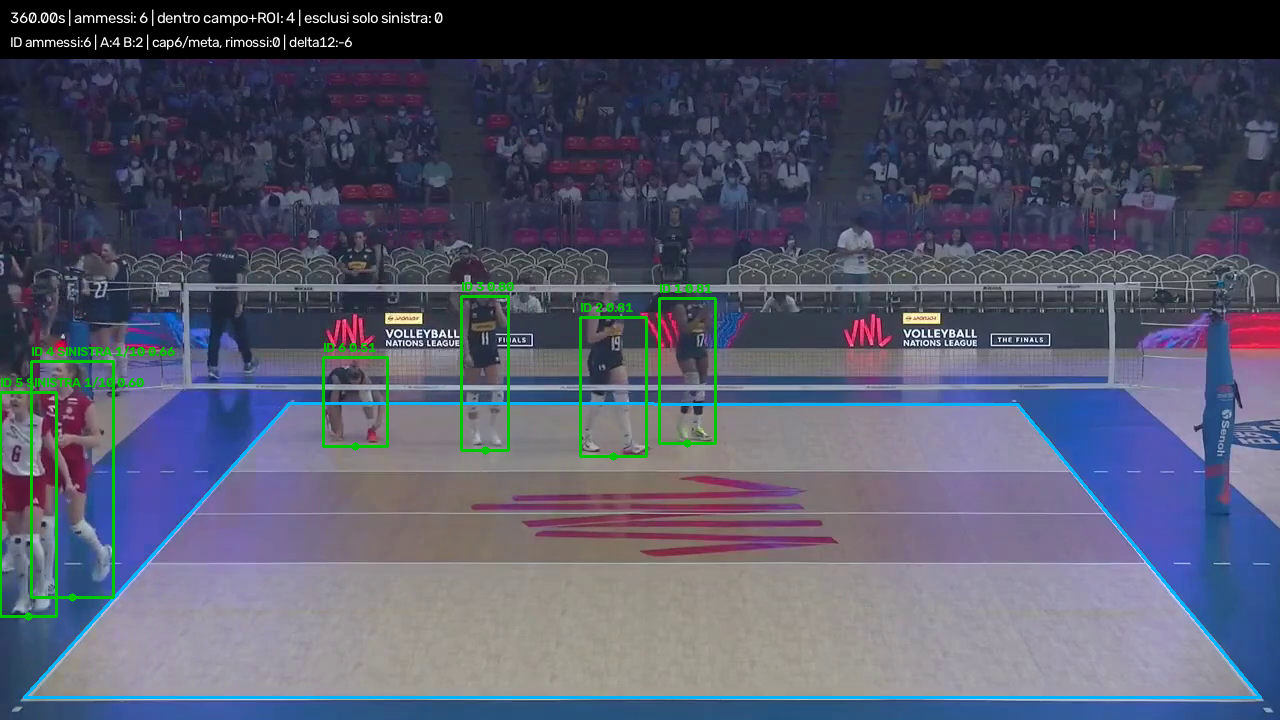

giocatori_frame_010830.png


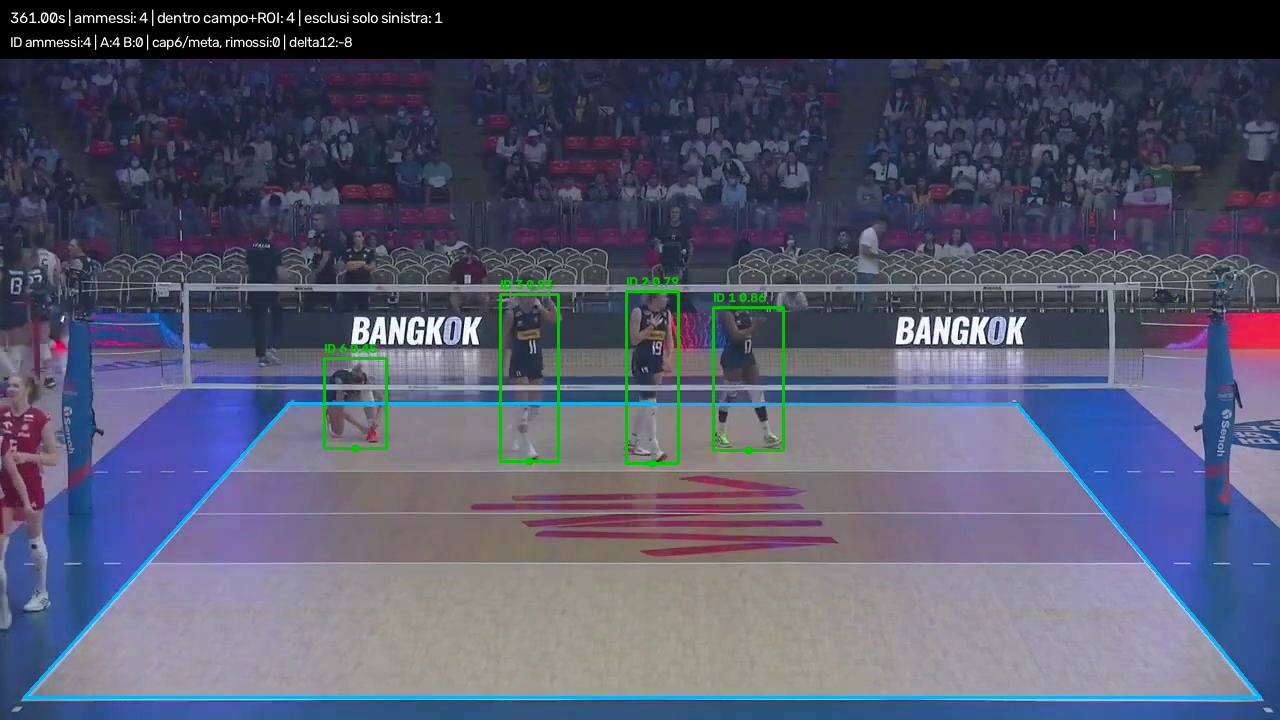

giocatori_frame_010860.png


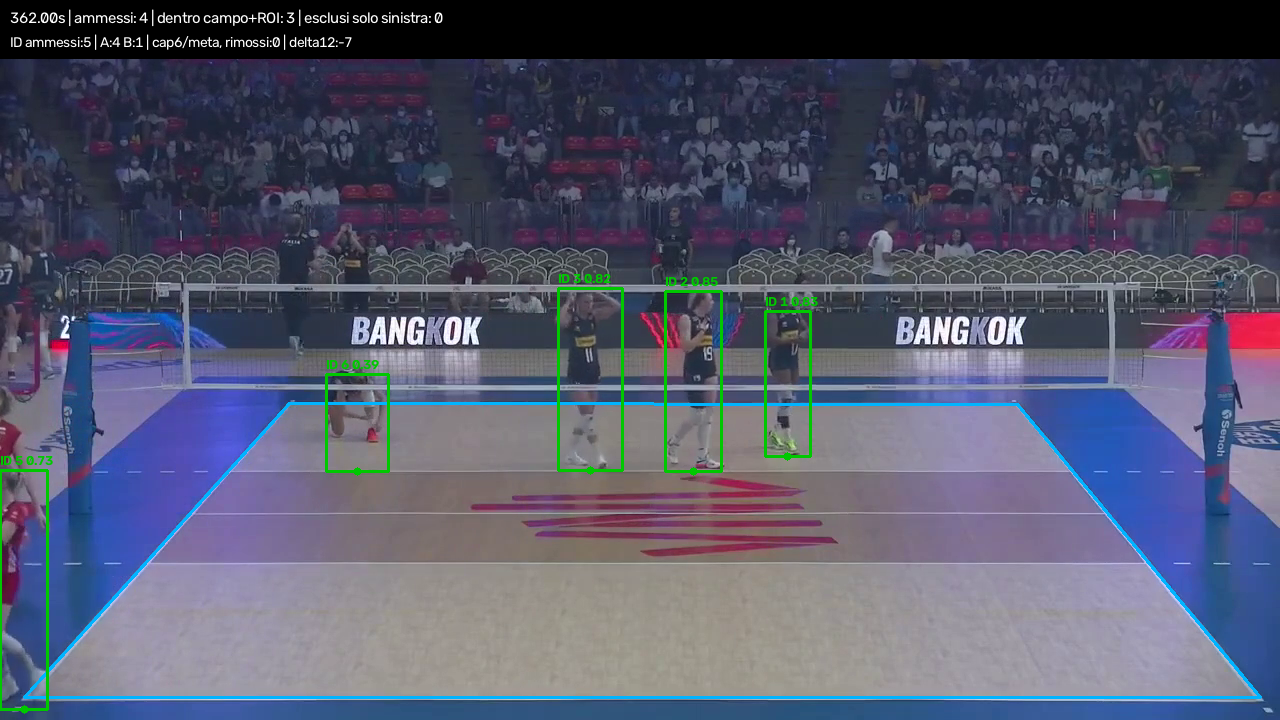

Verde: detection associata a ID; arancio: non ancora associata; grigio: esclusa dalla ROI.
Coordinate pavimento: centro bordo inferiore bbox, NON misura pose; salti e occlusioni possono alterare campo/meta.


In [12]:
from IPython.display import display, Image as DisplayImage
for path in sample_paths:
    print(path.name)
    display(DisplayImage(filename=str(path),width=960))
print('Verde: detection associata a ID; arancio: non ancora associata; grigio: esclusa dalla ROI.')
print('Coordinate pavimento: centro bordo inferiore bbox, NON misura pose; salti e occlusioni possono alterare campo/meta.')